In [1]:
import os
import sys
sys.path.append("..")

In [2]:
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)

In [3]:
from qnrl.environment import *
from qnrl.optimizer import *
from qnrl.modules import *
from qnrl.algorithms.qnrl import QnRL


# env = gym.make("ALE/Breakout-v5")
# env.unwrapped.get_action_meanings()


# env_cfg = EnvConfig(env_id="ALE/Breakout-v5", extra_args=dict(frameskip=1, repeat_action_probability=0.0), max_episode_steps=10_000)
env_cfg = EnvConfig(env_id="ALE/SpaceInvaders-v5", extra_args=dict(frameskip=1, repeat_action_probability=0.0), max_episode_steps=10_000)
# 
# env_cfg = ResizeObservation(env=env_cfg, shape=(84,84))
# env_cfg = GrayscaleObservation(env=env_cfg, keep_dim=True)
# env_cfg = FrameStackObservation(env=env_cfg, stack_size=4)
# env_cfg = ScaleObservation(env=env_cfg, scale=255.0) # x/255.0
# 
env_cfg = AtariPreprocessing(env=env_cfg, noop_max=30, frame_skip=4, screen_size=84, terminal_on_life_loss=True, grayscale_obs=True, scale_obs=True)
env_cfg = FrameStackObservation(env=env_cfg, stack_size=4)
env_cfg = FireResetEnvWrapper(env=env_cfg) # In Breakout the agent must do "FIRE" action to release ball on reset and after every life is lost.
#
# env_cfg = FlattenObservation(env=env_cfg) # Flatten multidimensional to 1D.
# 
z_min = -10
z_max = 10


seed = 0
n_actions = env_cfg.make().action_space.n
num_atoms = 2**5
batch_size = 32


m_moment = 1
n_reuploads = 1
# n_layers = 3
n_layers = 13
# model = QuantumNativeQNetwork(
#     din=4*84*84,
#     n_actions=n_actions,
#     n_returns=num_atoms,
#     z_min=z_min,
#     z_max=z_max,
#     n_layers=n_layers,
#     m_moment=m_moment,
#     n_reuploads=n_reuploads,
#     rngs_kwargs=dict(default=seed),
#     pauli_enc=('RX',),
#     pauli_var=('RZ','RY','RZ',),
#     # imprimitive='offset-CZ',
#     imprimitive='circ-CZ',
#     input_multiplex_activation='tanh',
# )


model = QuantumNativeQNetworkConv(
    din=1, # Greyscale.
    w=84,
    h=84,
    frame_stack=4,
    conv_douts=[32, 64, 64],
    conv_kernel_size=[(8,8), (4,4), (3,3)],
    conv_strides=[(4,4), (2,2), (1,1)],
    ###
    n_actions=n_actions,
    n_returns=num_atoms,
    z_min=z_min,
    z_max=z_max,
    n_layers=n_layers,
    m_moment=m_moment,
    n_reuploads=n_reuploads,
    rngs_kwargs=dict(default=seed),
    pauli_enc=('RX',),
    # pauli_enc=('ZZ',),
    pauli_var=('RZ','RY','RZ',),
    # imprimitive='offset-CZ',
    imprimitive='circ-CZ',
    input_multiplex_activation='tanh',
)


# Experiment configuration.
alg_cfg = QnRL(
    # buffer_size=1_000_000,
    buffer_size=10_000,
    seed=seed,
    batch_size=batch_size,
    # total_timesteps=10_000_000,
    # total_timesteps=100_000,
    total_timesteps=200_000,
    # learning_starts=80_000,
    learning_starts=800,
    policy_update_frequency=4,
    # target_update_frequency=10000,
    target_update_frequency=100,
    gamma=0.99, # default
    tau=1.0,
    eps_start=1,
    eps_end=0.01,
    # eps_exploration=0.10, # default
    eps_exploration=0.5,
    env=env_cfg,
    model=model,
    # optimizer=Adam(learning_rate=2.5e-4),
    optimizer=Partition(
        transforms={
            'trainable_quantum': AdamW(learning_rate=1e-2, b1=0.7, b2=0.999, weight_decay=5e-3),
            # 'trainable_quantum': AdamW(learning_rate=1e-3, b1=0.7, b2=0.999, weight_decay=5e-3),
            # 'trainable_classical': AdamW(learning_rate=2.5e-4, b1=0.7, b2=0.999, weight_decay=5e-3),
            'trainable_classical': Adam(learning_rate=2.5e-4),
        },
        pytree={
            'circ_weights_var': 'trainable_quantum',
            'circ_weights_enc_obs_kernel': 'trainable_quantum', # w
            'linear_input_projection': {
                'bias': 'trainable_classical',
                'kernel': 'trainable_classical',
            },
            # 'convs': {
            #     '0': {
            #         'bias': 'trainable_classical',
            #         'kernel': 'trainable_classical',
            #     },
            #     '1': {
            #         'bias': 'trainable_classical',
            #         'kernel': 'trainable_classical',
            #     },
            #     '2': {
            #         'bias': 'trainable_classical',
            #         'kernel': 'trainable_classical',
            #     },
            # },
            'convs': {
                'convs_0': {
                    'bias': 'trainable_classical',
                    'kernel': 'trainable_classical',
                },
                'convs_1': {
                    'bias': 'trainable_classical',
                    'kernel': 'trainable_classical',
                },
                'convs_2': {
                    'bias': 'trainable_classical',
                    'kernel': 'trainable_classical',
                },
            },
        },
    ),
)

A.L.E: Arcade Learning Environment (version 0.11.2+ecc1138)
[Powered by Stella]


In [4]:
# d = alg_cfg.to_dict()
# # QnRL.from_dict(d).model
# print(d['model'])
# print(QnRL.from_dict(d).model)

In [5]:
alg_cfg.optimizer.make(alg_cfg.model)

GradientTransformationExtraArgs(init=<function partition.<locals>.init_fn at 0x1281b45e0>, update=<function partition.<locals>.update_fn at 0x128216a20>)

In [6]:
env_cfg.make().unwrapped.get_action_meanings()

['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']

In [7]:
nnx.display(alg_cfg)

In [8]:
env = env_cfg.make()
obs = env.reset()[0]
obs.shape

(4, 84, 84)

In [9]:
from qnrl.tools import get_model_total_parameter_count
get_model_total_parameter_count(model)

173654

In [ ]:
train_history_df, train_report = alg_cfg.train()

  0%|          | 802/200000 [01:01<2:12:11, 25.11step/s, train/step=768, train/episode_reward=90, train/episode_length=191, train/episode_time=7.29]

In [ ]:
eval_seed = 1024
n_seeds = 10
eval_episode_rewards = []

fps = 15
video_seconds = 1*60

key = jax.random.PRNGKey(seed=eval_seed)
for _ in range(n_seeds):
    # Generate a new random key.
    key, subkey = jax.random.split(key=key)
    seed_eval = int(subkey[0])
    eval_history_df, eval_report = alg_cfg.eval(total_timesteps=video_seconds*fps, seed=seed_eval)
    eval_episode_rewards.append(eval_report['eval/episode_reward'])

# Convert to numpy array.
eval_episode_rewards = jnp.array(eval_episode_rewards)

 15%|█▍        | 132/900 [00:07<00:46, 16.58step/s, eval/step=132, eval/episode_reward=3, eval/episode_length=133, eval/episode_time=7.91]


In [ ]:
print(f"mean: {eval_episode_rewards.mean()}")
print(f"std: {eval_episode_rewards.std()}")

mean: 3.2
std: 0.9797958971132715


In [ ]:
from IPython.display import HTML
HTML(eval_report['eval/video'].to_html5_video())

Text(0, 0.5, 'episode_reward')

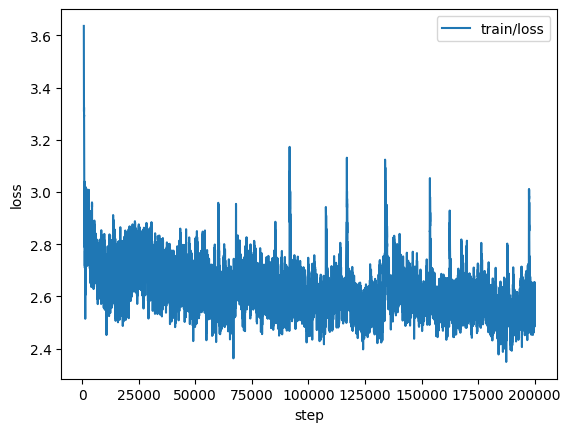

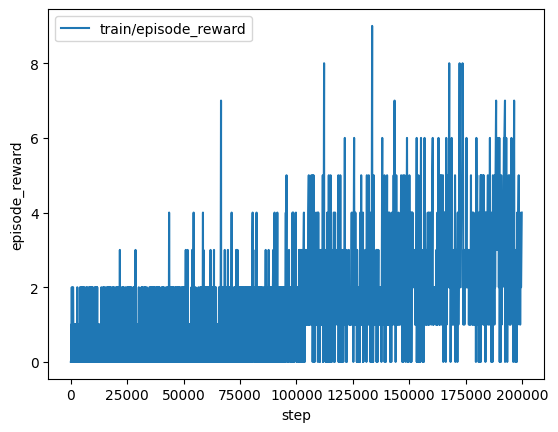

In [ ]:
import matplotlib.pyplot as plt

# history_dict = qnrl.tools.listofdict_to_dictoflist(qnrl.tools.load_train_results(metric_filepath))
# metric_manager.load()
# history_dict = metric_manager.get_dataframe()

plt.figure()
ax = plt.gca()
# plt.plot(history_dict['train/loss_step'].dropna(), history_dict['train/loss'].dropna())
train_history_df.set_index('train/step')[['train/loss']].dropna().plot(kind="line", ax=ax)
plt.xlabel('step')
plt.ylabel('loss')

plt.figure()
ax = plt.gca()
# plt.plot(history_dict['train/episode_step'].dropna(), history_dict['train/episode_reward'].dropna())
train_history_df.set_index('train/step')[['train/episode_reward']].dropna().plot(kind="line", ax=ax)
plt.xlabel('step')
plt.ylabel('episode_reward')